In [1]:
import sys
print(sys.executable)

/venv/main/bin/python


In [2]:
!{sys.executable} -m pip install gdown numpy pandas torch torchvision scikit-learn imbalanced-learn optuna timm huggingface_hub "transformers>=4.57,<5" "einops>=0.8,<1" matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 89.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 12.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 48.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 157.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 110.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 154.5 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 58.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 99.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 109.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.8/807.8 kB 23.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 112.5 MB/s  0:00:00
  Attempting uninstall: huggingface_hub╸━━━━━━━━━ 27/35 [optuna]learn]4]
    Found ex

In [ ]:
from sklearn import show_versions
show_versions()

In [2]:
import os
from pathlib import Path
import glob
import numpy as np
import pandas as pd
from IPython.display import display
import torch
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torch.amp import autocast, GradScaler
from sklearn.model_selection import StratifiedGroupKFold
from imblearn.metrics import geometric_mean_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import optuna
import time
sys.path.insert(0, os.getcwd())
import model_lib
import importlib
import json

In [11]:
import gdown
gdown.download(id="1YfjJWvsQgZYKwkn9vAMIGq-6XVF8gjcX",quiet=False)


Downloading...
From (original): https://drive.google.com/uc?id=1YfjJWvsQgZYKwkn9vAMIGq-6XVF8gjcX
From (redirected): https://drive.google.com/uc?id=1YfjJWvsQgZYKwkn9vAMIGq-6XVF8gjcX&confirm=t&uuid=7046a7db-440b-47de-a072-2b44c49b7ae5
To: /sleep_waveform.pt
100%|██████████| 9.39G/9.39G [02:35<00:00, 60.4MB/s]


'sleep_waveform.pt'

In [3]:
class EEGDataset(Dataset):
    def __init__(self, pt_filepath, split="development"):
        """
        Args:
            pt_filepath (str): Saved (N, 2, 30, 200) Sleep-EDF waveform patches.
            split (str): "development" for CV, or "test" for held-out evaluation.
        """
        print(f"Memory-mapping dataset from {pt_filepath}...")
        # Tensors and ordinary string/list metadata support weights_only=True.
        checkpoint = torch.load(pt_filepath, map_location="cpu", weights_only=True, mmap=True)

        self.data = checkpoint['patches']
        # Select one participant partition without copying the waveform tensor.
        self.indices = np.flatnonzero(np.asarray(checkpoint['splits']) == split)
        self.labels = checkpoint['labels'][self.indices]
        self.groups = np.asarray(checkpoint['groups'])[self.indices]

        self.channels = checkpoint['channels']
        self.sfreq = checkpoint['sfreq']
        self.amplitude = checkpoint['preprocessing']['amplitude']
        self.class_to_idx = checkpoint['class_map']
        self.idx_to_class = {value: key for key, value in self.class_to_idx.items()}

        print("Mapped source shape:", tuple(self.data.shape))
        print("Input per epoch:", tuple(self.data.shape[1:]), "= channels, seconds, samples/second")
        print("Channels:", self.channels, "| Sampling rate:", self.sfreq, "Hz | Scale:", self.amplitude)
        print(f"{split.capitalize()} samples:", len(self.labels))
        print("Participants:", len(set(self.groups)))
    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Preserve (channels, 30 one-second patches, 200 samples) and stored amplitude.
        x = self.data[self.indices[idx]].float()
        y = self.labels[idx].long()

        return x, y

def get_stats(subset):
    """Diagnostic mean/std per EEG channel, across epochs and waveform samples.

    Input batches: (B, C, 30, 200). Flatten only the two time axes to (B, C, 6000).
    These statistics are not applied to the pretrained CBraMod input: the export
    already uses microvolts / 100. Call on a training subset when inspecting data.
    """
    loader = DataLoader(subset, batch_size=32, shuffle=False, num_workers=0)
    sum_ = torch.zeros(subset[0][0].shape[0], dtype=torch.float64)
    sum_sq = torch.zeros_like(sum_)
    total_samples = 0

    for waveforms, _ in loader:
        waveforms = waveforms.double().flatten(start_dim=2)
        sum_ += waveforms.sum(dim=(0, 2))
        sum_sq += waveforms.square().sum(dim=(0, 2))
        total_samples += waveforms.shape[0] * waveforms.shape[2]

    mean = sum_ / total_samples
    variance = sum_sq / total_samples - mean.square()
    std = variance.clamp_min(0).sqrt()
    return mean.float(), std.float()

class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_f1 = -float('inf')
        self.early_stop = False

    def __call__(self, val_f1):
        if val_f1 > self.best_f1 + self.min_delta:
            self.best_f1 = val_f1
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
class ApplyTransform(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

def calculate_metrics(targets, outputs):
    """Five-stage metrics from epoch-level argmax predictions.

    MGm = mean(sqrt(specificity_i * recall_i)) across the five stages,
    matching the paper: compute per-class G-means first, then average.
    Per-class F1 order: W, N1, N2, N3, REM; undefined class ratios use zero.
    """
    outputs = outputs.detach().float().cpu()
    targets = targets.view(-1).detach().cpu().numpy().astype(int)
    preds = outputs.argmax(dim=1).numpy()

    acc = accuracy_score(targets, preds)
    bal_acc = balanced_accuracy_score(targets, preds)
    prec = precision_score(targets, preds, labels=range(5), average='macro', zero_division=0)
    rec = recall_score(targets, preds, labels=range(5), average='macro', zero_division=0)
    per_class_f1 = f1_score(targets, preds, labels=range(5), average=None, zero_division=0)
    f1 = per_class_f1.mean()
    kappa = cohen_kappa_score(targets, preds, labels=range(5))

    mgm = geometric_mean_score(targets, preds, labels=range(5), average=None).mean()

    return acc, mgm, prec, rec, bal_acc, f1, kappa, per_class_f1

def train_and_evaluate(model, train_loader, val_loader, criterion, optimizer, scheduler, device, use_sched, use_es, max_epochs=50):
    # Development/inner validation only: this function selects an epoch using val_loader.
    scaler = GradScaler('cuda', enabled=device.type == 'cuda')
    early_stopping = EarlyStopping(patience=10, min_delta=0.001)

    # Select the checkpoint and stop training using validation Macro-F1.
    best_mgm = 0.0
    best_acc = 0.0
    best_prec = 0.0
    best_rec = 0.0
    best_bal_acc = 0.0
    best_f1 = -float('inf')
    best_kappa = 0.0
    best_per_class_f1 = np.zeros(5)
    best_epoch, best_state = 0, None
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    for epoch in range(max_epochs):
        epoch_start_time = time.time()

        model.train()
        train_loss = 0.0

        all_train_targets, all_train_outputs = [], []

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device=device, dtype=torch.float32), labels.to(device=device, dtype=torch.long)

            optimizer.zero_grad()

            with autocast('cuda', enabled=device.type == 'cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * len(labels)

            all_train_targets.append(labels.detach().cpu())
            all_train_outputs.append(outputs.detach().cpu())

        model.eval()
        val_loss = 0.0
        all_targets, all_outputs = [], []

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device=device, dtype=torch.float32), labels.to(device=device, dtype=torch.long)

                with autocast('cuda', enabled=device.type == 'cuda'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * len(labels)
                all_targets.append(labels.cpu())
                all_outputs.append(outputs.cpu())

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)

        train_targets_tensor = torch.cat(all_train_targets)
        train_outputs_tensor = torch.cat(all_train_outputs)
        train_acc, train_mgm, train_prec, train_rec, train_bal_acc, train_f1, train_kappa, _ = calculate_metrics(train_targets_tensor, train_outputs_tensor)

        targets_tensor = torch.cat(all_targets)
        outputs_tensor = torch.cat(all_outputs)
        acc, mgm, prec, rec, bal_acc, f1, kappa, per_class_f1 = calculate_metrics(targets_tensor, outputs_tensor)
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(acc)

        epoch_duration = time.time() - epoch_start_time

        print(f"Epoch {epoch+1:02d}/{max_epochs} | Time: {epoch_duration:.2f}s")
        print(f"  [Train] Loss: {avg_train_loss:.4f} | Acc: {train_acc:.4f} | BAcc: {train_bal_acc:.4f} | MGm: {train_mgm:.4f} | Prec: {train_prec:.4f} | Rec: {train_rec:.4f} | F1: {train_f1:.4f} | Kappa: {train_kappa:.4f}")
        print(f"  [Val]   Loss: {avg_val_loss:.4f} | Acc: {acc:.4f} | BAcc: {bal_acc:.4f} | MGm: {mgm:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f} | Kappa: {kappa:.4f}")

        if use_sched:
            scheduler.step()

        if f1 > best_f1:
            best_acc = acc
            best_mgm = mgm
            best_prec = prec
            best_rec = rec
            best_bal_acc = bal_acc
            best_f1 = f1
            best_kappa = kappa
            best_per_class_f1 = per_class_f1.copy()
            best_epoch = epoch + 1
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            best_targets = targets_tensor.numpy().astype(int)
            best_preds = outputs_tensor.float().argmax(dim=1).numpy()

        if use_es:
            early_stopping(f1)
            if early_stopping.early_stop:
                print(f"Early stopping triggered at epoch {epoch+1}!")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
        model.eval()
        print(f'Restored best validation-Macro-F1 weights from epoch {best_epoch}.')

    if best_state is not None:
        cm = confusion_matrix(best_targets, best_preds, labels=range(5))
        print(f'Validation EEG-epoch confusion matrix at epoch {best_epoch} (argmax over five stages)')
        print('Rows = true [W, N1, N2, N3, REM]; columns = predicted stages')
        print(cm)
        ConfusionMatrixDisplay(cm, display_labels=['W', 'N1', 'N2', 'N3', 'REM']).plot(cmap='Blues', values_format='d', colorbar=False)
        plt.title(f'Validation (EEG epochs) - best Macro-F1 epoch {best_epoch}')
        plt.tight_layout()
        plt.show()

        epochs = range(1, len(train_losses) + 1)
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epochs, train_losses, label='Train Loss')
        plt.plot(epochs, val_losses, label='Val Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(epochs, train_accuracies, label='Train Accuracy')
        plt.plot(epochs, val_accuracies, label='Val Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.suptitle('EEG-epoch metrics; training measured during updates')
        plt.tight_layout()
        plt.show()

    return best_mgm, best_acc, best_prec, best_rec, best_bal_acc, best_f1, best_kappa, best_per_class_f1

In [4]:
# Run from the directory containing this notebook and model_lib.py.
PROJECT_DIR = os.getcwd()

DATA_DIR = os.path.join(PROJECT_DIR, "dataset")
MODEL_DIR = os.path.join(PROJECT_DIR, "spec_model")

DATA_PATH = os.path.join(PROJECT_DIR, "sleep_waveform.pt")
CHECKPOINT = os.path.join(PROJECT_DIR, "pretrained_weights", "pretrained_weights.pth")

# Create model directory if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

torch.manual_seed(42)
np.random.seed(42)

dataset = EEGDataset(pt_filepath=DATA_PATH)
print(f"Found {len(dataset)} total samples across {len(dataset.class_to_idx)} classes.")

Using device: cuda
Memory-mapping dataset from /sleep_waveform.pt...
Mapped source shape: (195469, 2, 30, 200)
Input per epoch: (2, 30, 200) = channels, seconds, samples/second
Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz'] | Sampling rate: 200 Hz | Scale: microvolts / 100
Development samples: 170537
Participants: 66
Found 170537 total samples across 5 classes.



==================== Fold 1/5 ====================
Class weights [W, N1, N2, N3, REM]: [0.3  0.51 0.3  0.24 0.3 ]
Epoch 01/80 | Time: 12.38s
  [Train] Loss: 0.6978 | Acc: 0.7360 | BAcc: 0.6452 | MGm: 0.7657 | Prec: 0.6753 | Rec: 0.6452 | F1: 0.6565 | Kappa: 0.6339
  [Val]   Loss: 0.6237 | Acc: 0.7659 | BAcc: 0.6693 | MGm: 0.7835 | Prec: 0.7321 | Rec: 0.6693 | F1: 0.6906 | Kappa: 0.6746
Epoch 02/80 | Time: 11.97s
  [Train] Loss: 0.6070 | Acc: 0.7755 | BAcc: 0.6975 | MGm: 0.8046 | Prec: 0.7229 | Rec: 0.6975 | F1: 0.7076 | Kappa: 0.6897
  [Val]   Loss: 0.6195 | Acc: 0.7467 | BAcc: 0.6254 | MGm: 0.7522 | Prec: 0.7502 | Rec: 0.6254 | F1: 0.6512 | Kappa: 0.6477
Epoch 03/80 | Time: 11.38s
  [Train] Loss: 0.5882 | Acc: 0.7823 | BAcc: 0.7063 | MGm: 0.8109 | Prec: 0.7306 | Rec: 0.7063 | F1: 0.7161 | Kappa: 0.6991
  [Val]   Loss: 0.5890 | Acc: 0.7828 | BAcc: 0.7370 | MGm: 0.8275 | Prec: 0.7217 | Rec: 0.7370 | F1: 0.7245 | Kappa: 0.7016
Epoch 04/80 | Time: 11.78s
  [Train] Loss: 0.5773 | Acc: 0.7

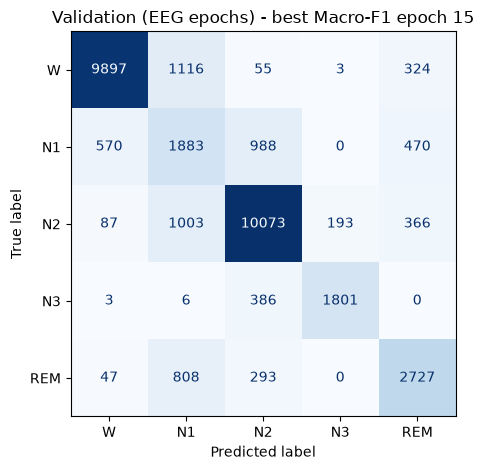

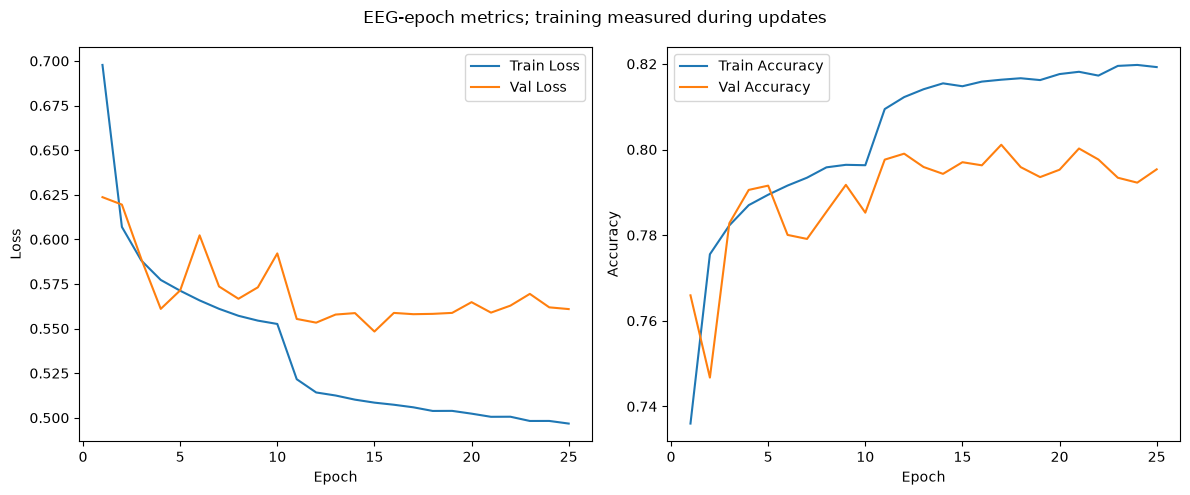

Saved best validation checkpoint: AttnSleep_sleep_waveform_fold_1.pt

--- Fold 1 Metrics at Best Validation Macro-F1 ---
Acc: 0.7970 | BAcc: 0.7466 | MGm: 0.8377 | Prec: 0.7563 | Rec: 0.7466 | F1: 0.7499 | Kappa: 0.7214

==================== Fold 2/5 ====================
Class weights [W, N1, N2, N3, REM]: [0.3  0.51 0.3  0.23 0.3 ]
Epoch 01/80 | Time: 12.04s
  [Train] Loss: 0.7054 | Acc: 0.7329 | BAcc: 0.6415 | MGm: 0.7628 | Prec: 0.6719 | Rec: 0.6415 | F1: 0.6535 | Kappa: 0.6298
  [Val]   Loss: 0.5940 | Acc: 0.7575 | BAcc: 0.6772 | MGm: 0.7913 | Prec: 0.7385 | Rec: 0.6772 | F1: 0.6946 | Kappa: 0.6654
Epoch 02/80 | Time: 11.55s
  [Train] Loss: 0.6060 | Acc: 0.7761 | BAcc: 0.6962 | MGm: 0.8035 | Prec: 0.7231 | Rec: 0.6962 | F1: 0.7072 | Kappa: 0.6906
  [Val]   Loss: 0.6099 | Acc: 0.7364 | BAcc: 0.6808 | MGm: 0.7908 | Prec: 0.7427 | Rec: 0.6808 | F1: 0.6851 | Kappa: 0.6419
Epoch 03/80 | Time: 11.91s
  [Train] Loss: 0.5905 | Acc: 0.7810 | BAcc: 0.7036 | MGm: 0.8089 | Prec: 0.7297 | Rec: 

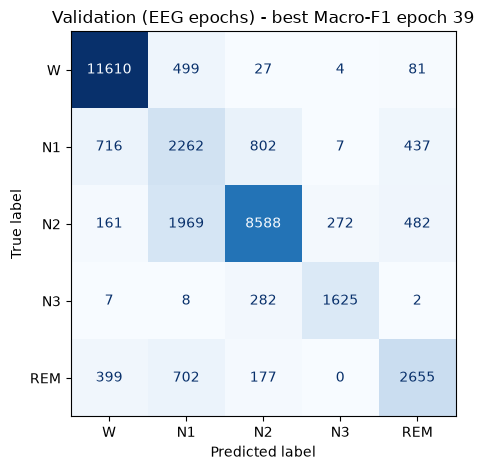

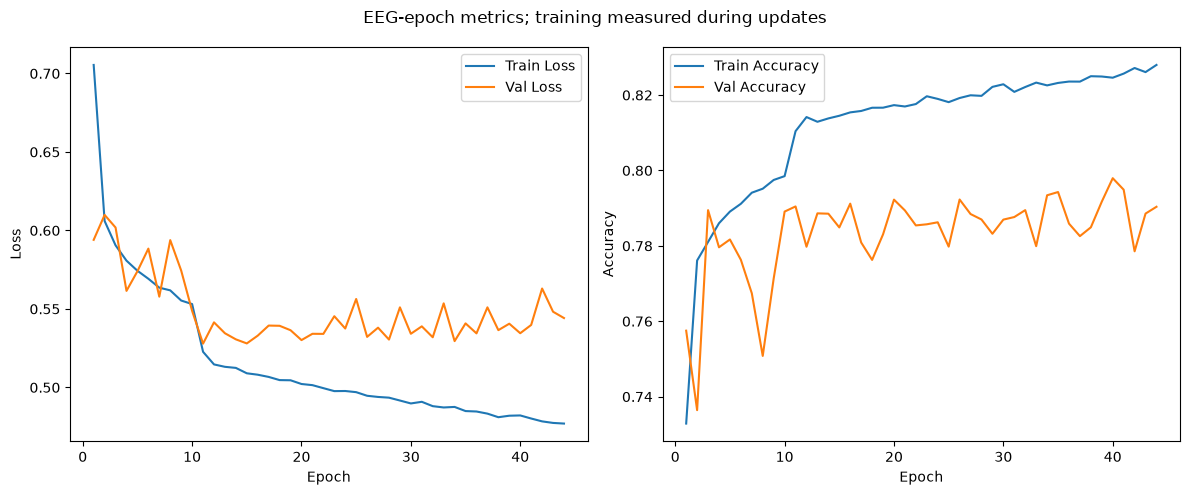

Saved best validation checkpoint: AttnSleep_sleep_waveform_fold_2.pt

--- Fold 2 Metrics at Best Validation Macro-F1 ---
Acc: 0.7917 | BAcc: 0.7508 | MGm: 0.8398 | Prec: 0.7527 | Rec: 0.7508 | F1: 0.7490 | Kappa: 0.7134

==================== Fold 3/5 ====================
Class weights [W, N1, N2, N3, REM]: [0.3  0.5  0.3  0.24 0.3 ]
Epoch 01/80 | Time: 12.31s
  [Train] Loss: 0.6992 | Acc: 0.7350 | BAcc: 0.6455 | MGm: 0.7656 | Prec: 0.6739 | Rec: 0.6455 | F1: 0.6563 | Kappa: 0.6325
  [Val]   Loss: 0.6557 | Acc: 0.7329 | BAcc: 0.6870 | MGm: 0.7963 | Prec: 0.7215 | Rec: 0.6870 | F1: 0.6848 | Kappa: 0.6395
Epoch 02/80 | Time: 11.63s
  [Train] Loss: 0.5987 | Acc: 0.7775 | BAcc: 0.7032 | MGm: 0.8085 | Prec: 0.7261 | Rec: 0.7032 | F1: 0.7124 | Kappa: 0.6926
  [Val]   Loss: 0.6127 | Acc: 0.7644 | BAcc: 0.6806 | MGm: 0.7916 | Prec: 0.7434 | Rec: 0.6806 | F1: 0.6956 | Kappa: 0.6733
Epoch 03/80 | Time: 11.87s
  [Train] Loss: 0.5792 | Acc: 0.7850 | BAcc: 0.7129 | MGm: 0.8154 | Prec: 0.7353 | Rec: 

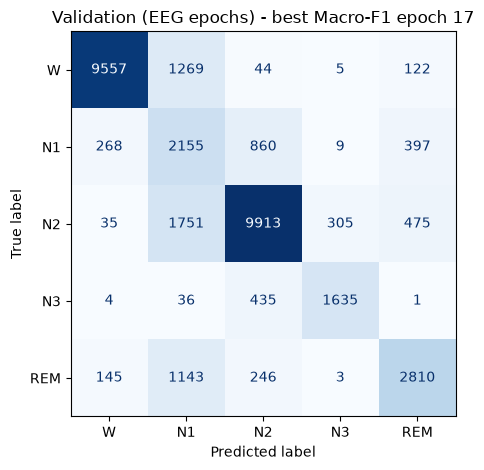

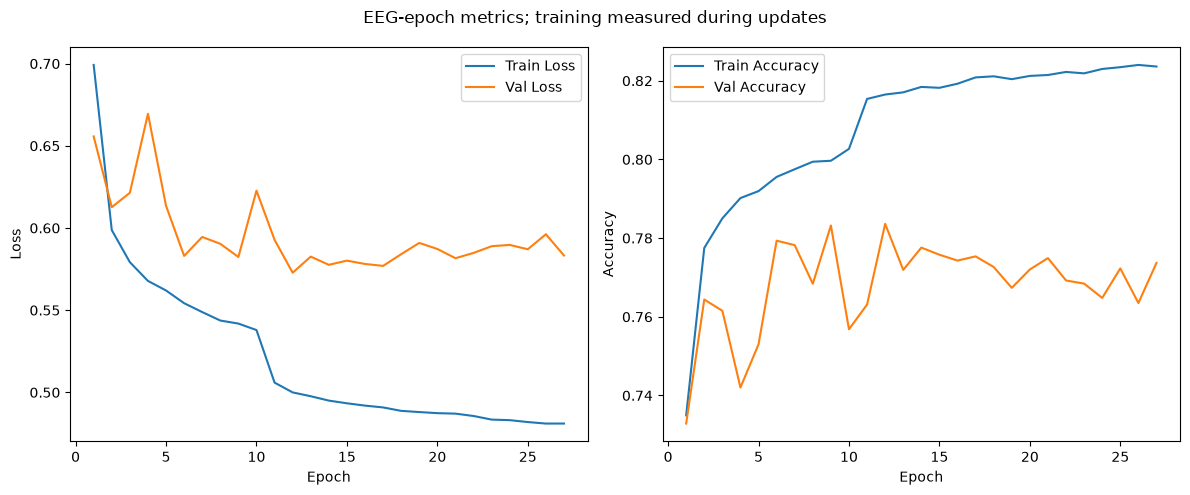

Saved best validation checkpoint: AttnSleep_sleep_waveform_fold_3.pt

--- Fold 3 Metrics at Best Validation Macro-F1 ---
Acc: 0.7754 | BAcc: 0.7337 | MGm: 0.8309 | Prec: 0.7460 | Rec: 0.7337 | F1: 0.7318 | Kappa: 0.6951

==================== Fold 4/5 ====================
Class weights [W, N1, N2, N3, REM]: [0.3  0.49 0.3  0.23 0.3 ]
Epoch 01/80 | Time: 12.34s
  [Train] Loss: 0.6959 | Acc: 0.7337 | BAcc: 0.6426 | MGm: 0.7623 | Prec: 0.6730 | Rec: 0.6426 | F1: 0.6543 | Kappa: 0.6307
  [Val]   Loss: 0.6304 | Acc: 0.7610 | BAcc: 0.6676 | MGm: 0.7853 | Prec: 0.7502 | Rec: 0.6676 | F1: 0.6870 | Kappa: 0.6694
Epoch 02/80 | Time: 11.83s
  [Train] Loss: 0.6056 | Acc: 0.7734 | BAcc: 0.6944 | MGm: 0.8015 | Prec: 0.7223 | Rec: 0.6944 | F1: 0.7060 | Kappa: 0.6866
  [Val]   Loss: 0.6409 | Acc: 0.7386 | BAcc: 0.6257 | MGm: 0.7404 | Prec: 0.7620 | Rec: 0.6257 | F1: 0.6299 | Kappa: 0.6360
Epoch 03/80 | Time: 11.83s
  [Train] Loss: 0.5870 | Acc: 0.7815 | BAcc: 0.7068 | MGm: 0.8105 | Prec: 0.7311 | Rec: 

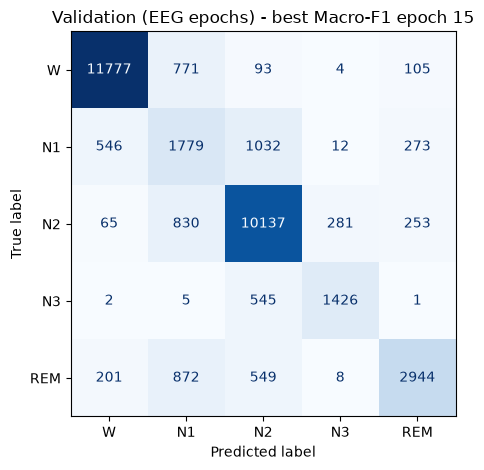

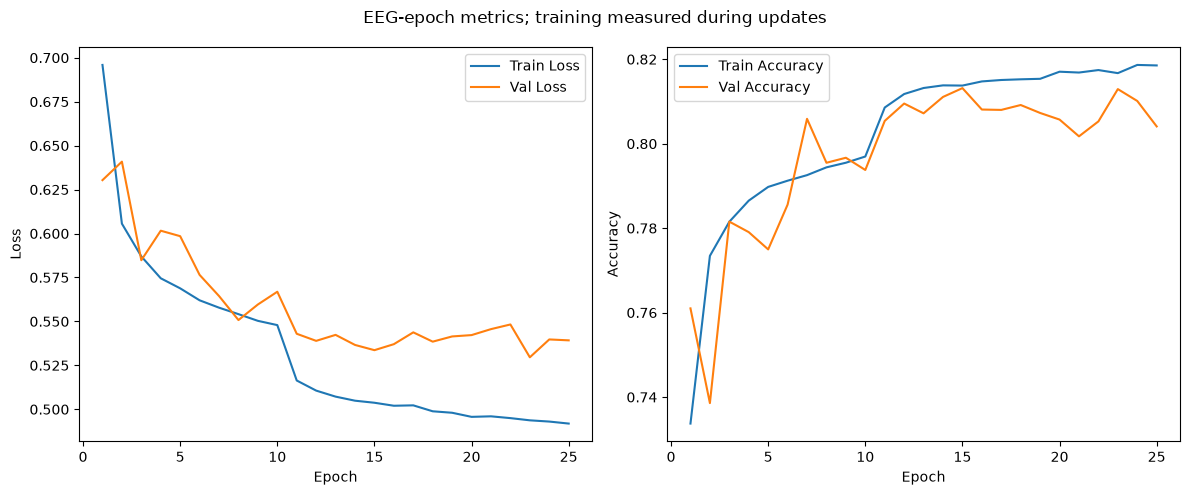

Saved best validation checkpoint: AttnSleep_sleep_waveform_fold_4.pt

--- Fold 4 Metrics at Best Validation Macro-F1 ---
Acc: 0.8132 | BAcc: 0.7306 | MGm: 0.8283 | Prec: 0.7641 | Rec: 0.7306 | F1: 0.7437 | Kappa: 0.7389

==================== Fold 5/5 ====================
Class weights [W, N1, N2, N3, REM]: [0.3  0.5  0.3  0.24 0.3 ]
Epoch 01/80 | Time: 12.08s
  [Train] Loss: 0.7070 | Acc: 0.7307 | BAcc: 0.6344 | MGm: 0.7566 | Prec: 0.6658 | Rec: 0.6344 | F1: 0.6460 | Kappa: 0.6248
  [Val]   Loss: 0.6531 | Acc: 0.7650 | BAcc: 0.7017 | MGm: 0.8067 | Prec: 0.7151 | Rec: 0.7017 | F1: 0.7069 | Kappa: 0.6802
Epoch 02/80 | Time: 11.64s
  [Train] Loss: 0.6039 | Acc: 0.7732 | BAcc: 0.6933 | MGm: 0.8014 | Prec: 0.7203 | Rec: 0.6933 | F1: 0.7042 | Kappa: 0.6855
  [Val]   Loss: 0.6254 | Acc: 0.7688 | BAcc: 0.6890 | MGm: 0.7939 | Prec: 0.7411 | Rec: 0.6890 | F1: 0.7013 | Kappa: 0.6807
Epoch 03/80 | Time: 11.59s
  [Train] Loss: 0.5879 | Acc: 0.7810 | BAcc: 0.7037 | MGm: 0.8088 | Prec: 0.7296 | Rec: 

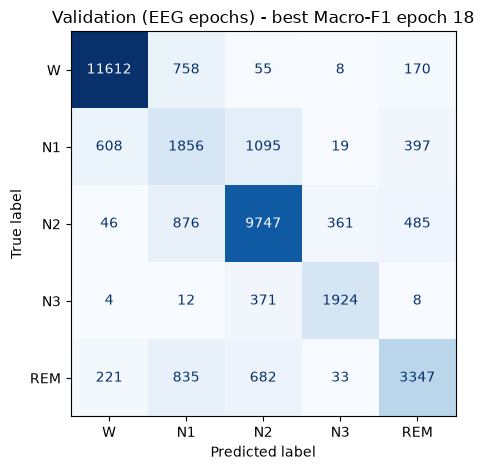

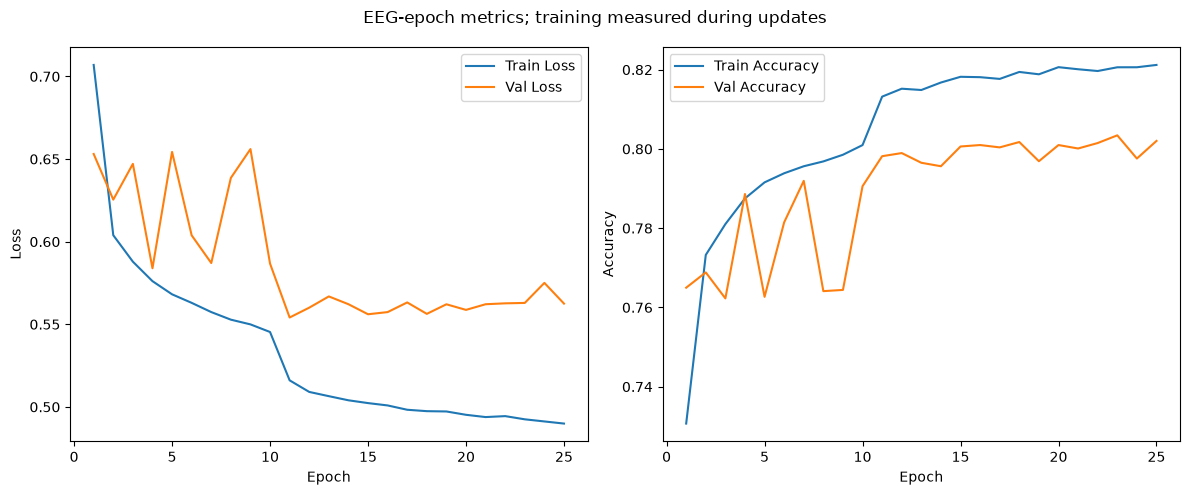

Saved best validation checkpoint: AttnSleep_sleep_waveform_fold_5.pt

--- Fold 5 Metrics at Best Validation Macro-F1 ---
Acc: 0.8017 | BAcc: 0.7437 | MGm: 0.8347 | Prec: 0.7506 | Rec: 0.7437 | F1: 0.7461 | Kappa: 0.7286

==================== Final CV Results (5/5 folds completed) ====================


Overall                                                              \
       Accuracy Balanced Accuracy      F1   Kappa     MGm Precision  Recall   
Fold 1   0.7970            0.7466  0.7499  0.7214  0.8377    0.7563  0.7466   
Fold 2   0.7917            0.7508  0.7490  0.7134  0.8398    0.7527  0.7508   
Fold 3   0.7754            0.7337  0.7318  0.6951  0.8309    0.7460  0.7337   
Fold 4   0.8132            0.7306  0.7437  0.7389  0.8283    0.7641  0.7306   
Fold 5   0.8017            0.7437  0.7461  0.7286  0.8347    0.7506  0.7437   

       Per-class F1                                  
                  W      N1      N2      N3     REM  
Fold 1       0.8998  0.4315  0.8567  0.8591  0.7027  
Fold 2       0.9246  0.4681  0.8046  0.8481  0.6996  
Fold 3       0.9099  0.4292  0.8269  0.8038  0.6894  
Fold 4       0.9295  0.4504  0.8475  0.7687  0.7225  
Fold 5       0.9255  0.4466  0.8308  0.8250  0.7028

Overall                                     \
                  Accuracy Balanced Accuracy               F1   
Mean ± SD  0.7958 ± 0.0124   0.7411 ± 0.0077  0.7441 ± 0.0065   

                                                                               \
                     Kappa              MGm        Precision           Recall   
Mean ± SD  0.7195 ± 0.0148  0.8343 ± 0.0042  0.7540 ± 0.0061  0.7411 ± 0.0077   

              Per-class F1                                                     \
                         W               N1               N2               N3   
Mean ± SD  0.9178 ± 0.0112  0.4452 ± 0.0141  0.8333 ± 0.0180  0.8210 ± 0.0323   

                            
                       REM  
Mean ± SD  0.7034 ± 0.0107

In [11]:
importlib.reload(model_lib)

# AttnSleep is trained from scratch; author config uses Adam lr=1e-3.
lr = 1e-3
batch_size = 128
weight_decay = 1e-3
n_splits = 5
max_epochs = 80

# Linux/Colab/Vast workers. For a macOS notebook use 0 / None / False below.
num_workers = 4
prefetch_factor = 2
persistent_workers = True
pin_memory = True

# Regenerates development folds: use the same split for the CNN comparison.
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
y = dataset.labels.numpy()
groups = np.array(dataset.groups)

# Balanced Accuracy is Macro-Recall when all five stages are present.
cv_metrics = {
    'acc': [],
    'bal_acc': [],
    'f1': [],
    'kappa': [],
    'mgm': [],
    'prec': [],
    'rec': [],
}
cv_per_class_f1 = []
stage_names = ['W', 'N1', 'N2', 'N3', 'REM']

for fold, (train_idx, val_idx) in enumerate(sgkf.split(np.zeros(len(y)), y, groups)):
    #if fold > 1: break  # chỉ train và đánh giá Fold 1 2
    print(f"\n{'='*20} Fold {fold + 1}/{n_splits} {'='*20}")

    train_subset_raw = Subset(dataset, train_idx)
    val_subset_raw = Subset(dataset, val_idx)

    # The saved waveform is already microvolts / 100. Do not z-score or divide again.
    # Optional diagnostics only: mean, std = get_stats(train_subset_raw)
    # Reference: https://github.com/wjq-learning/CBraMod/blob/main/datasets/isruc_dataset.py
    normalization = None

    train_subset = ApplyTransform(train_subset_raw, transform=normalization)
    val_subset = ApplyTransform(val_subset_raw, transform=normalization)

    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, prefetch_factor=prefetch_factor,
                                num_workers=num_workers, pin_memory=pin_memory, persistent_workers=persistent_workers)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, prefetch_factor=prefetch_factor,
                                num_workers=num_workers, pin_memory=pin_memory, persistent_workers=persistent_workers)

    # Author's single-channel architecture; adapter converts this export to 100 Hz.
    # channel_index=0: Fpz-Cz; channel_index=1: Pz-Oz. No pretrained checkpoint.
    model = model_lib.AttnSleep(channel_index=0).to(device)
    # Author's class-weight formula (mu tuned for Sleep-EDF-20), reused here.
    # Count ONLY training labels; do not use validation/test labels for weights.
    # https://github.com/emadeldeen24/AttnSleep/blob/main/utils/util.py
    counts = np.bincount(y[train_idx], minlength=5)
    mu = np.array([1.5, 2.0, 1.5, 1.0, 1.5]) / 5
    weights = np.round(np.maximum(np.log(mu * counts.sum() / counts), 1.0) * mu, 2)
    class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
    criterion = torch.nn.CrossEntropyLoss(weight=class_weights)
    print("Class weights [W, N1, N2, N3, REM]:", weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay, amsgrad=True)
    # Epochs 1-10: 1e-3; epoch 11 onward: 1e-4 (one reduction only).
    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer, milestones=[10], gamma=0.1
    )

    best_mgm, best_acc, best_prec, best_rec, best_bal_acc, best_f1, best_kappa, best_per_class_f1 = train_and_evaluate(
        model, train_loader, val_loader, criterion, optimizer, scheduler, device, use_sched=True, use_es=True, max_epochs=max_epochs
    )

    # train_and_evaluate has already restored the best validation checkpoint.
    checkpoint_path = Path(f"{model.__class__.__name__}_{Path(DATA_PATH).stem}_fold_{fold + 1}.pt")
    torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, checkpoint_path)
    print("Saved best validation checkpoint:", checkpoint_path)

    cv_metrics['mgm'].append(best_mgm)
    cv_metrics['acc'].append(best_acc)
    cv_metrics['prec'].append(best_prec)
    cv_metrics['rec'].append(best_rec)
    cv_metrics['bal_acc'].append(best_bal_acc)
    cv_metrics['f1'].append(best_f1)
    cv_metrics['kappa'].append(best_kappa)
    cv_per_class_f1.append(best_per_class_f1)

    print(f"\n--- Fold {fold + 1} Metrics at Best Validation Macro-F1 ---")
    print(f"Acc: {best_acc:.4f} | BAcc: {best_bal_acc:.4f} | MGm: {best_mgm:.4f} | Prec: {best_prec:.4f} | Rec: {best_rec:.4f} | F1: {best_f1:.4f} | Kappa: {best_kappa:.4f}")

print(f"\n{'='*20} Final CV Results ({len(cv_metrics['acc'])}/{n_splits} folds completed) {'='*20}")
# All columns describe the same selected checkpoint in each fold.
cv_results = pd.DataFrame(cv_metrics, index=[f"Fold {i + 1}" for i in range(len(cv_metrics['acc']))])
cv_results.columns = pd.MultiIndex.from_tuples([
    ('Overall', name) for name in ['Accuracy', 'Balanced Accuracy', 'F1', 'Kappa', 'MGm', 'Precision', 'Recall']
])
per_class_results = pd.DataFrame(
    cv_per_class_f1, index=cv_results.index,
    columns=pd.MultiIndex.from_product([['Per-class F1'], stage_names]),
)
cv_results = pd.concat([cv_results, per_class_results], axis=1)
cv_summary = pd.DataFrame(
    [[f"{cv_results[col].mean():.4f} ± {cv_results[col].std(ddof=0):.4f}" for col in cv_results.columns]],
    columns=cv_results.columns, index=['Mean ± SD'],
)
display(cv_results.round(4), cv_summary)


Collected Fold 1: 33099 validation samples
Collected Fold 2: 33774 validation samples
Collected Fold 3: 33623 validation samples
Collected Fold 4: 34511 validation samples
Collected Fold 5: 35530 validation samples
Pooled validation: 170537 EEG epochs; each included once


Overall                                       \
                               Accuracy Balanced Accuracy       F1     Kappa   
Pooled validation (5/5 folds)  0.795956          0.741126  0.74457  0.719765   

                                                            Per-class F1  \
                                    MGm Precision    Recall            W   
Pooled validation (5/5 folds)  0.834761  0.752448  0.741126     0.918619   

                                                                       
                                     N1        N2        N3       REM  
Pooled validation (5/5 folds)  0.445067  0.833837  0.821908  0.703417

Rows = true [W, N1, N2, N3, REM]; columns = predicted stages
[[54453  4413   274    24   802]
 [ 2708  9935  4777    47  1974]
 [  394  6429 48458  1412  2061]
 [   20    67  2019  8411    12]
 [ 1013  4360  1947    44 14483]]


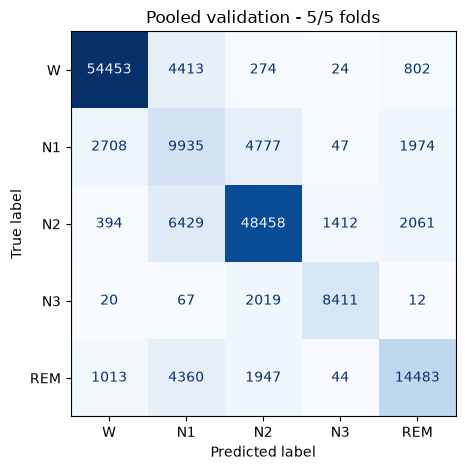

In [12]:
# Pool validation predictions from the saved best checkpoint of EACH fold.
# Reuse the SAME dataset, SGKF splits, model architecture and input settings.
# No training; these are pooled validation results, not independent test results.
completed_folds = len(cv_results)
fold_checkpoints = [
    Path(f"{model.__class__.__name__}_{Path(DATA_PATH).stem}_fold_{i + 1}.pt")
    for i in range(completed_folds)
]
assert completed_folds > 0 and all(p.is_file() for p in fold_checkpoints), "Missing fold checkpoints: per-fold metrics alone cannot recover predictions."

# Restore the current model afterward so the held-out test cell still uses it.
current_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
pooled_targets, pooled_outputs, pooled_indices = [], [], []
for fold, (_, val_idx) in enumerate(sgkf.split(np.zeros(len(y)), y, groups)):
    if fold >= completed_folds: break
    model.load_state_dict(torch.load(fold_checkpoints[fold], map_location="cpu", weights_only=True))
    model.eval()
    fold_val_loader = DataLoader(
        Subset(dataset, val_idx), batch_size=batch_size, shuffle=False,
        num_workers=0, pin_memory=device.type == "cuda",
    )
    with torch.inference_mode():
        for inputs, labels in fold_val_loader:
            inputs = inputs.to(device=device, dtype=torch.float32, non_blocking=True)
            with autocast('cuda', enabled=device.type == 'cuda'):
                outputs = model(inputs)
            pooled_targets.append(labels.cpu())
            pooled_outputs.append(outputs.float().cpu())
    pooled_indices.append(val_idx)
    print(f"Collected Fold {fold + 1}: {len(val_idx)} validation samples")

model.load_state_dict(current_state)
model.eval()
del current_state
pooled_targets = torch.cat(pooled_targets)
pooled_outputs = torch.cat(pooled_outputs)
pooled_indices = np.concatenate(pooled_indices)
assert len(np.unique(pooled_indices)) == len(pooled_indices), "Duplicate validation samples."
assert np.array_equal(pooled_targets.numpy(), y[pooled_indices]), "Validation order does not match labels."
if completed_folds == n_splits:
    assert len(pooled_indices) == len(dataset), "Incomplete development coverage."

acc, mgm, prec, rec, bal_acc, f1, kappa, per_class_f1 = calculate_metrics(pooled_targets, pooled_outputs)
pooled_results = pd.DataFrame(
    [[acc, bal_acc, f1, kappa, mgm, prec, rec, *per_class_f1]],
    columns=cv_results.columns,
    index=[f"Pooled validation ({completed_folds}/{n_splits} folds)"],
)
print(f"Pooled validation: {len(pooled_targets)} EEG epochs; each included once")
display(pooled_results)

pooled_preds = pooled_outputs.argmax(dim=1).numpy()
pooled_cm = confusion_matrix(pooled_targets.numpy(), pooled_preds, labels=range(5))
print("Rows = true [W, N1, N2, N3, REM]; columns = predicted stages")
print(pooled_cm)
ConfusionMatrixDisplay(pooled_cm, display_labels=stage_names).plot(
    cmap='Blues', values_format='d', colorbar=False,
)
plt.title(f"Pooled validation - {completed_folds}/{n_splits} folds")
plt.tight_layout()
plt.show()


Memory-mapping dataset from /sleep_waveform.pt...
Mapped source shape: (195469, 2, 30, 200)
Input per epoch: (2, 30, 200) = channels, seconds, samples/second
Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz'] | Sampling rate: 200 Hz | Scale: microvolts / 100
Test samples: 24932
Participants: 12
Collected test probabilities from Fold 1/5
Collected test probabilities from Fold 2/5
Collected test probabilities from Fold 3/5
Collected test probabilities from Fold 4/5
Collected test probabilities from Fold 5/5
Held-out test: 24932 EEG epochs, 12 participants; 5-model ensemble


Overall                                                  \
               Accuracy Balanced Accuracy        F1     Kappa       MGm   
Held-out test  0.796446          0.764654  0.750965  0.725067  0.849365   

                                  Per-class F1                                \
              Precision    Recall            W        N1        N2        N3   
Held-out test  0.747263  0.764654     0.886711  0.414611  0.847147  0.835478   

                        
                   REM  
Held-out test  0.77088

Rows = true [W, N1, N2, N3, REM]; columns = predicted stages
[[5021  619   91    9  235]
 [ 252 1101  412    2  314]
 [  29  971 8463  464  451]
 [   9   19  338 2143    1]
 [  39  520  298    2 3129]]


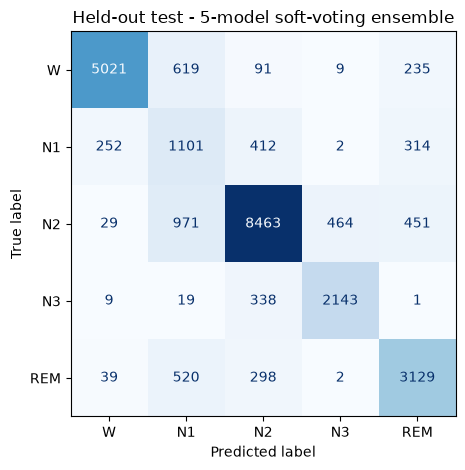

In [13]:
# Equal-weight soft voting across all K best-validation fold checkpoints.
# Use the SAME DATA_PATH, architecture and input settings as training.
K = n_splits
fold_checkpoints = [
    Path(f"{model.__class__.__name__}_{Path(DATA_PATH).stem}_fold_{fold + 1}.pt")
    for fold in range(K)
]
assert len(cv_results) == K, "Complete all K folds before evaluating the K-model ensemble."
assert all(p.is_file() for p in fold_checkpoints), "Missing best-validation fold checkpoints."

test_dataset = EEGDataset(pt_filepath=DATA_PATH, split="test")
assert set(dataset.groups).isdisjoint(set(test_dataset.groups))
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=0, pin_memory=device.type == "cuda",
)

current_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
test_probs_list, test_targets = [], []
for fold in range(K):
    model.load_state_dict(torch.load(fold_checkpoints[fold], map_location="cpu", weights_only=True))
    model.eval()
    fold_probs = []
    with torch.inference_mode():
        for inputs, labels in test_loader:
            inputs = inputs.to(device=device, dtype=torch.float32, non_blocking=True)
            with autocast('cuda', enabled=device.type == 'cuda'):
                logits = model(inputs)
            fold_probs.append(torch.softmax(logits.float(), dim=1).cpu())
            if fold == 0:
                test_targets.append(labels.cpu())
    test_probs_list.append(torch.cat(fold_probs))
    print(f"Collected test probabilities from Fold {fold + 1}/{K}")

model.load_state_dict(current_state)
model.eval()
del current_state
# [K, N, 5] -> [N, 5]: average probabilities, then choose the final stage.
mean_test_probs = torch.stack(test_probs_list).mean(dim=0)
test_targets = torch.cat(test_targets)
assert torch.equal(test_targets, test_dataset.labels.cpu()), "Test label order mismatch."
final_test_preds = mean_test_probs.argmax(dim=1)
acc, mgm, prec, rec, bal_acc, f1, kappa, per_class_f1 = calculate_metrics(test_targets, mean_test_probs)
test_results = pd.DataFrame(
    [[acc, bal_acc, f1, kappa, mgm, prec, rec, *per_class_f1]],
    columns=cv_results.columns, index=[f"Held-out test"],
)
print(f"Held-out test: {len(test_dataset)} EEG epochs, {len(set(test_dataset.groups))} participants; {K}-model ensemble")
display(test_results)

test_preds = final_test_preds.numpy()
cm = confusion_matrix(test_targets.numpy(), test_preds, labels=range(5))
print("Rows = true [W, N1, N2, N3, REM]; columns = predicted stages")
print(cm)
ConfusionMatrixDisplay(cm, display_labels=stage_names).plot(
    cmap='Blues', values_format='d', colorbar=False,
)
plt.title(f"Held-out test - {K}-model soft-voting ensemble")
plt.tight_layout()
plt.show()

# Store ensemble results separately from the earlier single-model results.
result_prefix = Path(MODEL_DIR) / f"{model.__class__.__name__}_{Path(DATA_PATH).stem}_heldout_test_soft_voting_{K}models"
test_results.to_csv(f"{result_prefix}_metrics.csv")
pd.DataFrame({
    'source_index': test_dataset.indices,
    'participant': test_dataset.groups,
    'target': test_targets.numpy(),
    'prediction': test_preds,
}).to_csv(f"{result_prefix}_predictions.csv", index=False)
